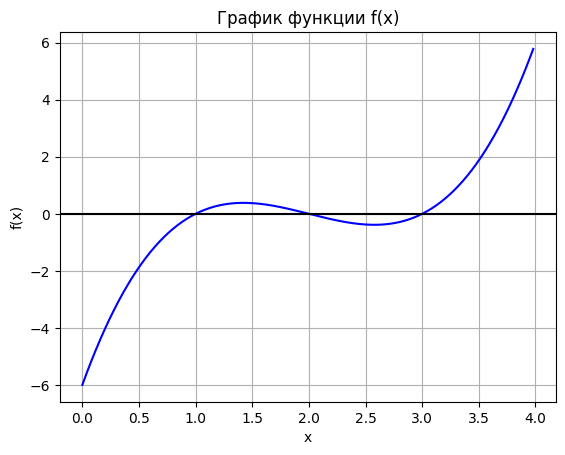

In [1]:
#Задача 1.
#Пункт 1

import matplotlib.pyplot as plt

def f(x):
    return x**3 - 6 * x**2 + 11 * x - 6

x_points = []
y_points = []
cur = 0.0
while cur <= 4.0:
    x_points.append(cur)
    y_points.append(f(cur))
    cur += 0.02

plt.plot(x_points, y_points, color="blue")
plt.axhline(0, color="black")
plt.grid(True)
plt.title("График функции f(x)")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.show()


In [5]:
#Пункт 2-3

def bisection(f, a, b, eps=1e-9, max_iter=200):
    fa, fb = f(a), f(b)
    if fa * fb > 0:
        raise ValueError(f"Нет смены знака на [{a}, {b}]: f(a)={fa}, f(b)={fb}")

    journal = []
    for k in range(1, max_iter + 1):
        c = (a + b) / 2
        fc = f(c)
        length = b - a

        journal.append({
            "iter": k,
            "a": a,
            "b": b,
            "c": c,
            "f(c)": fc,
            "length": length,
        })

        if fc == 0:
            return c, journal, "f_zero"
        if length < eps:
            return c, journal, "ok"

        if fa * fc < 0:
            b = c
            fb = fc
        else:
            a = c
            fa = fc

    return c, journal, "max_iter"

def print_journal(journal, title=""):
    if title:
        print(f"\n=== {title} ===")
    print(f"{'k':>3} | {'a':>12} | {'b':>12} | {'c':>12} | {'f(c)':>14} | {'b-a':>10}")
    print("-" * 80)
    for row in journal:
        print(f"{row['iter']:>3} | {row['a']:>12.6f} | {row['b']:>12.6f} | "
              f"{row['c']:>12.6f} | {row['f(c)']:>14.3e} | {row['length']:>10.2e}")

segments = [
    (0.4, 1.5),
    (1.4, 2.7),
    (2.2, 3.7)
]

for left, right in segments:
    found_x, log, state = bisection(f, left, right, eps=1e-9)
    print_journal(log, f"Отрезок [{left}, {right}] (статус: {state})")



=== Отрезок [0.4, 1.5] (статус: ok) ===
  k |            a |            b |            c |           f(c) |        b-a
--------------------------------------------------------------------------------
  1 |     0.400000 |     1.500000 |     0.950000 |     -1.076e-01 |   1.10e+00
  2 |     0.950000 |     1.500000 |     1.225000 |      3.095e-01 |   5.50e-01
  3 |     0.950000 |     1.225000 |     1.087500 |      1.527e-01 |   2.75e-01
  4 |     0.950000 |     1.087500 |     1.018750 |      3.645e-02 |   1.37e-01
  5 |     0.950000 |     1.018750 |     0.984375 |     -3.199e-02 |   6.87e-02
  6 |     0.984375 |     1.018750 |     1.001562 |      3.118e-03 |   3.44e-02
  7 |     0.984375 |     1.001562 |     0.992969 |     -1.421e-02 |   1.72e-02
  8 |     0.992969 |     1.001562 |     0.997266 |     -5.491e-03 |   8.59e-03
  9 |     0.997266 |     1.001562 |     0.999414 |     -1.173e-03 |   4.30e-03
 10 |     0.999414 |     1.001562 |     1.000488 |      9.758e-04 |   2.15e-03
 11 |    

In [3]:
#Пункт 4

import math

eps = 1e-9
intervals = [(0.4, 1.5), (1.4, 2.7), (2.2, 3.7)]

for a, b in intervals:
    root, journal, status = bisection(f, a, b, eps=eps)
    n_theor = math.ceil(math.log2((b - a) / eps)) + 1
    print(f"Отрезок [{a}, {b}]: шагов = {len(journal)}, по формуле = {n_theor}")


Отрезок [0.4, 1.5]: шагов = 32, по формуле = 32
Отрезок [1.4, 2.7]: шагов = 32, по формуле = 32
Отрезок [2.2, 3.7]: шагов = 32, по формуле = 32


In [6]:
#Пункт 5

tasks = [
    (0.4, 1.5, 1.0),
    (1.4, 2.7, 2.0),
    (2.2, 3.7, 3.0)
]

print("Точный | Найденный | Итераций | Δ (абс.) | δ (отн.)")
print("-" * 60)

for a, b, true_x in tasks:
    root, journal, status = bisection(f, a, b, eps=1e-9)
    d_abs = abs(root - true_x)
    d_rel = d_abs / abs(true_x)
    print(f"{true_x:.1f} | {root:.10f} | {len(journal)} | {d_abs:.2e} | {d_rel:.2e}")


Точный | Найденный | Итераций | Δ (абс.) | δ (отн.)
------------------------------------------------------------
1.0 | 1.0000000002 | 32 | 2.10e-10 | 2.10e-10
2.0 | 2.0000000003 | 32 | 2.56e-10 | 1.28e-10
3.0 | 3.0000000002 | 32 | 1.63e-10 | 5.43e-11
